# ETL e análise exploratória de dados clínicos e demográficos

Este notebook apresenta um fluxo didático de **leitura, validação, integração e exploração de dados** a partir de três fontes: pacientes, dados clínicos e referência geográfica.

> **Escopo:** os dados pertencem ao conjunto didático do projeto original e não devem ser interpretados como retrato epidemiológico ou socioeconômico da população brasileira.

O foco deste case é demonstrar fundamentos de **Data Analysis / ETL / EDA** com Python e Pandas.


## 1. Preparação do ambiente


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data" / "raw"
pd.set_option("display.max_columns", 30)

print("Diretório do projeto:", ROOT.resolve())


## 2. Leitura das fontes


In [ ]:
df_pacientes = pd.read_csv(DATA / "dados_pacientes" / "dados_pacientes.csv", sep=";")
df_clinicos = pd.read_csv(DATA / "dados_clinicos" / "dados_clinicos.csv", sep=";")
df_regiao = pd.read_csv(DATA / "estado_regiao" / "estado_regiao.csv", sep=";", encoding="latin-1")

resumo_fontes = pd.DataFrame({
    "Fonte": ["Pacientes", "Dados clínicos", "Estados/regiões"],
    "Linhas": [len(df_pacientes), len(df_clinicos), len(df_regiao)],
    "Colunas": [df_pacientes.shape[1], df_clinicos.shape[1], df_regiao.shape[1]]
})
display(resumo_fontes)


            Fonte  Linhas  Colunas
0       Pacientes    7999        9
1  Dados clínicos     590        4
2  Estados/regiões      27        5

### Leitura inicial

A base principal contém **7.999 pacientes**, enquanto a base clínica possui **590 registros**. Essa diferença é relevante: análises que dependem de peso ou colesterol terão uma amostra menor do que análises puramente demográficas.


## 3. Qualidade dos dados


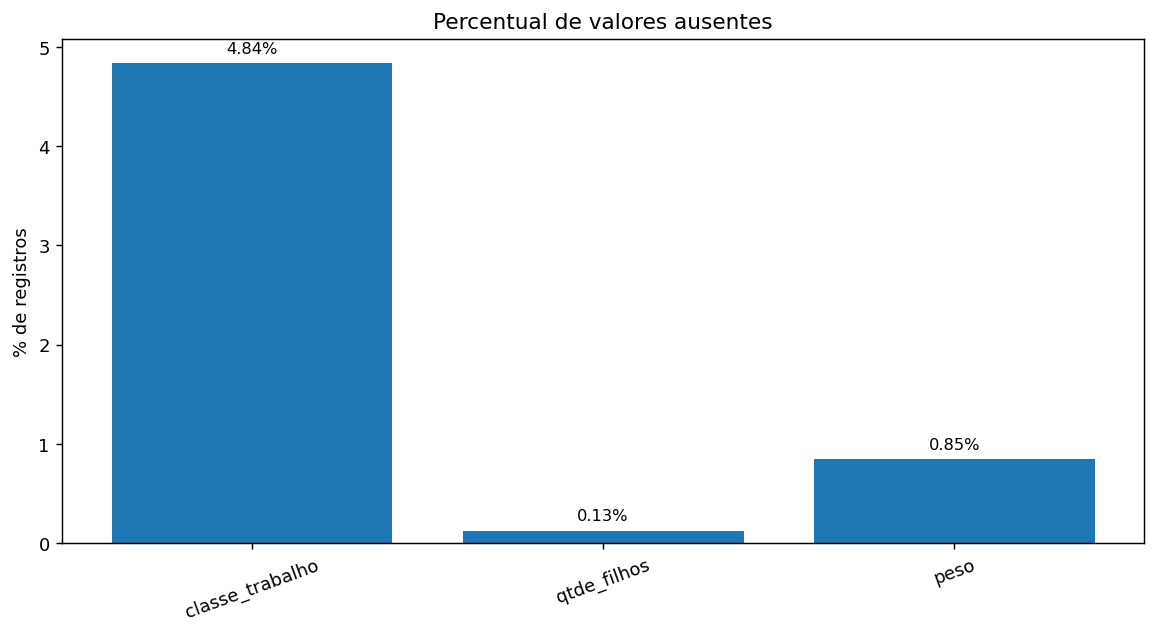

In [ ]:
def missing_summary(df, origem):
    out = df.isna().sum().rename("Ausentes").to_frame()
    out["Percentual"] = 100 * out["Ausentes"] / len(df)
    out["Origem"] = origem
    return out[out["Ausentes"] > 0].reset_index(names="Campo")

qualidade = pd.concat([
    missing_summary(df_pacientes, "Pacientes"),
    missing_summary(df_clinicos, "Dados clínicos"),
    missing_summary(df_regiao, "Regiões")
], ignore_index=True)

display(qualidade.round({"Percentual": 2}))

plt.figure(figsize=(8, 4))
plt.bar(qualidade["Campo"], qualidade["Percentual"])
plt.title("Percentual de valores ausentes")
plt.ylabel("% de registros")
plt.xticks(rotation=20)
plt.show()


### Interpretação

A ausência de dados é **concentrada e pequena**: `classe_trabalho` apresenta cerca de **4,84%** de valores ausentes, `qtde_filhos` cerca de **0,13%**, e `peso` aproximadamente **0,85%** na base clínica. Como os percentuais são distintos por variável, qualquer tratamento futuro deve considerar o objetivo analítico em vez de aplicar imputação automática de forma indiscriminada.


## 4. Integração das bases


In [ ]:
df = (
    df_pacientes
    .merge(df_regiao, on="id_estado", how="left", validate="many_to_one")
    .merge(df_clinicos, on="id_cliente", how="left", validate="one_to_one")
)

print("Linhas após integração:", len(df))
print("Pacientes com informação clínica:", df["colesterol"].notna().sum())
display(df.head())


Linhas após integração: 7999
Pacientes com informação clínica: 590


A integração preserva os **7.999 registros demográficos** e acrescenta os dados clínicos quando disponíveis. O uso de `validate` nos `merge`s também funciona como uma checagem estrutural: cada estado deve ter uma única referência geográfica e cada `id_cliente` deve ter no máximo um registro clínico.


## 5. Perfil etário


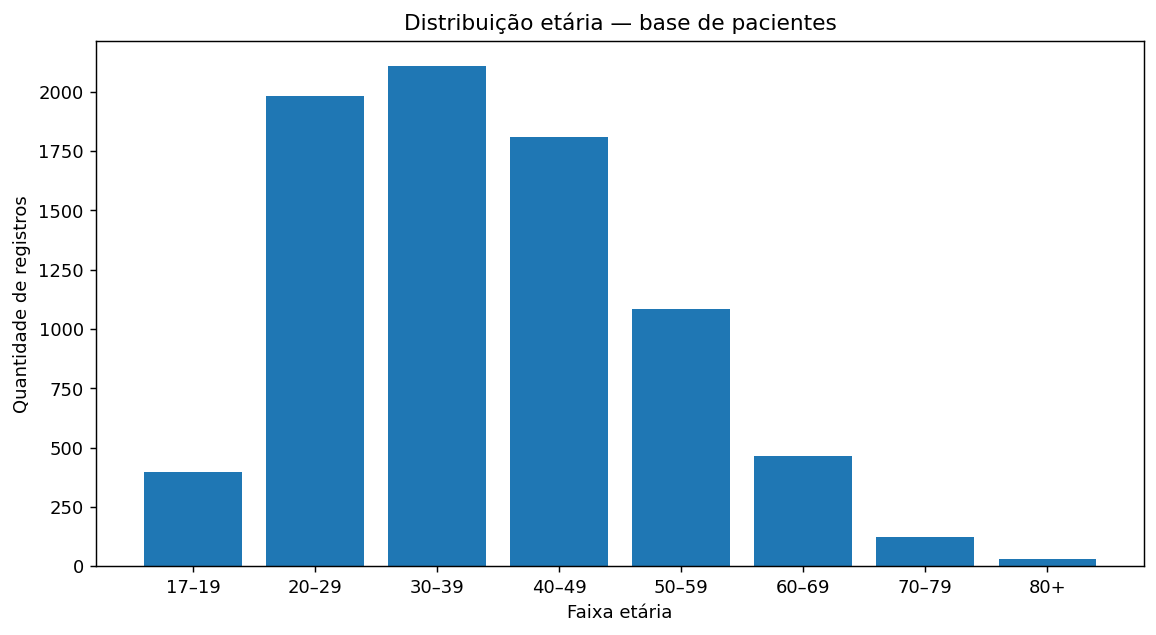

In [ ]:
plt.figure(figsize=(9, 4))
bins = [17, 20, 30, 40, 50, 60, 70, 80, 100]
plt.hist(df_pacientes["idade"], bins=bins, edgecolor="black")
plt.title("Distribuição etária — base de pacientes")
plt.xlabel("Idade")
plt.ylabel("Quantidade de registros")
plt.show()

display(df_pacientes["idade"].describe().round(1))


### Interpretação

A idade mediana é **37 anos** e a média é aproximadamente **38,5 anos**. A maior concentração está entre **20 e 49 anos**, portanto resultados agregados do conjunto devem ser interpretados à luz dessa distribuição.


## 6. Distribuição geográfica


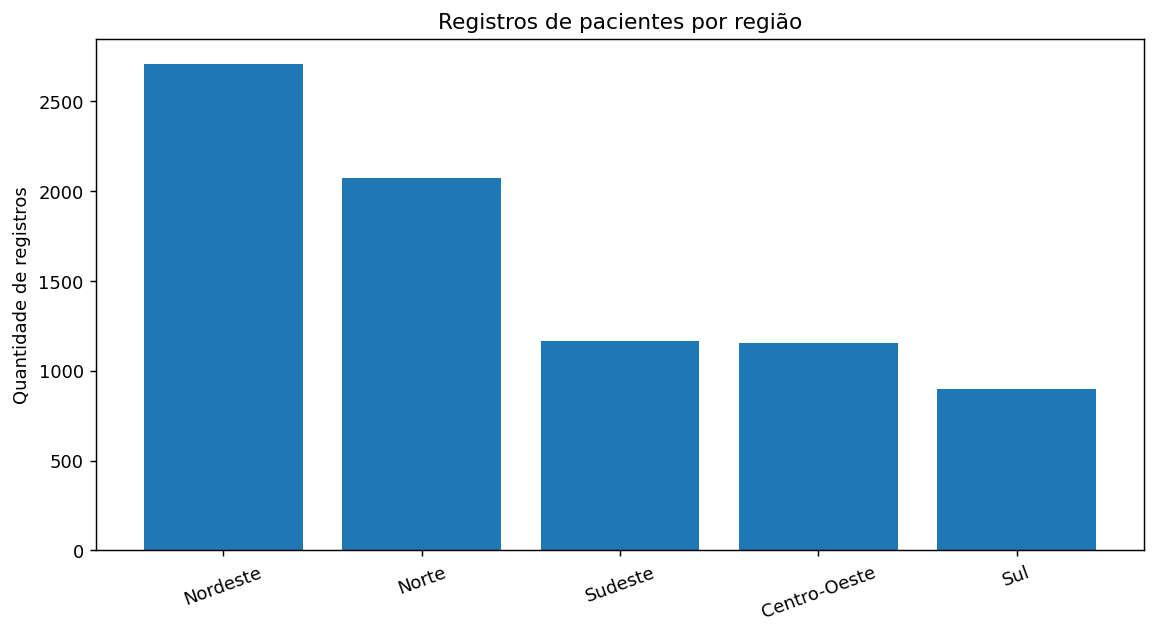

In [ ]:
regioes = df["regiao"].value_counts()

plt.figure(figsize=(8, 4))
regioes.plot(kind="bar")
plt.title("Registros de pacientes por região")
plt.xlabel("Região")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=20)
plt.show()

display(regioes.to_frame("Registros"))


### Interpretação

O conjunto não é geograficamente balanceado. **Nordeste e Norte concentram a maior parte dos registros**, enquanto Sul, Sudeste e Centro-Oeste têm participação menor. Isso impede tratar as proporções deste dataset como estimativas populacionais.


## 7. Escolaridade e renda


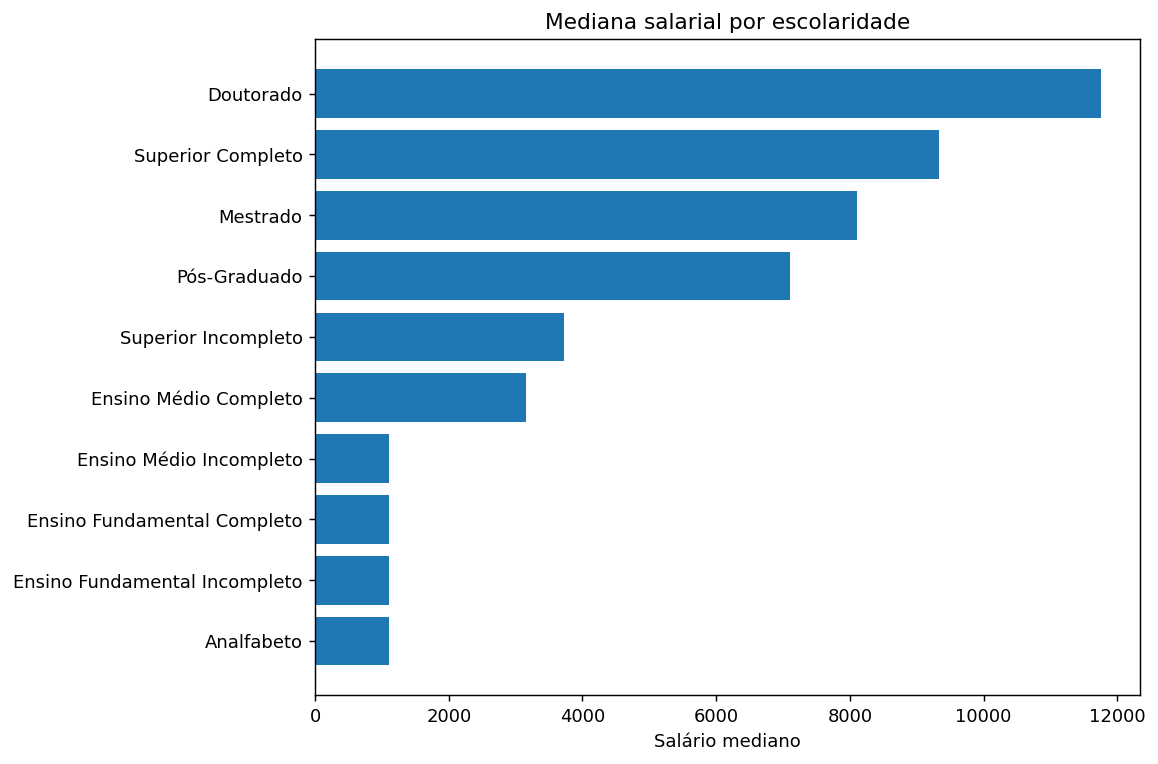

In [ ]:
renda_escolaridade = (
    df_pacientes
    .groupby("escolaridade", dropna=False)["salario"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
)

plt.figure(figsize=(9, 6))
renda_escolaridade["median"].sort_values().plot(kind="barh")
plt.title("Mediana salarial por escolaridade")
plt.xlabel("Salário mediano")
plt.ylabel("Escolaridade")
plt.show()

display(renda_escolaridade.round(2))


### Interpretação

O conjunto didático apresenta uma associação visual entre níveis mais altos de escolaridade e maiores medianas salariais. Entretanto, algumas categorias possuem **pouquíssimos registros** — por exemplo, certos níveis de ensino superior —, portanto esse gráfico é útil como exercício de EDA, mas **não sustenta inferência socioeconômica**.


## 8. Relação entre peso e colesterol


In [ ]:
clinicos_validos = df.dropna(subset=["peso", "colesterol"]).copy()
corr = clinicos_validos["peso"].corr(clinicos_validos["colesterol"])

plt.figure(figsize=(7, 5))
plt.scatter(clinicos_validos["peso"], clinicos_validos["colesterol"], alpha=0.55)
plt.title(f"Peso × colesterol — correlação de Pearson = {corr:.3f}")
plt.xlabel("Peso")
plt.ylabel("Colesterol")
plt.show()

print("Observações válidas:", len(clinicos_validos))
print("Correlação de Pearson:", round(corr, 3))


### Interpretação

Na amostra clínica, peso e colesterol apresentam **forte associação linear positiva** (correlação de Pearson próxima de **0,88**). Esse resultado é útil para demonstrar análise de relacionamento entre variáveis, mas **correlação não implica causalidade** e o conjunto é didático.


## 9. Conclusões

O case demonstra um fluxo básico, porém completo, de análise de dados:

- leitura de múltiplas fontes;
- auditoria de valores ausentes;
- validação de chaves durante a integração;
- análise de distribuições;
- comparação entre categorias;
- investigação de relacionamento entre variáveis;
- interpretação com ressalvas sobre representatividade e causalidade.

Os projetos seguintes deste repositório avançam desse contexto de EDA para **séries temporais, validação temporal e Machine Learning**.
